In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
data_path = Path("data/raw_fire_archive.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (309087, 15)

Columns:
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,34.6054,-117.3376,306.5,1.0,1.0,2003-01-02,1846,Terra,MODIS,64,6.03,289.0,6.9,D,2
1,35.2934,-118.4130,301.8,1.0,1.0,2003-01-02,1846,Terra,MODIS,49,6.03,285.5,5.5,D,0
2,35.2529,-118.1982,302.4,1.0,1.0,2003-01-02,1846,Terra,MODIS,52,6.03,283.7,6.2,D,0
3,34.6014,-117.3407,308.7,1.0,1.0,2003-01-03,2102,Aqua,MODIS,65,6.03,294.0,6.9,D,2
4,35.3549,-118.9819,301.8,1.0,1.0,2003-01-03,2102,Aqua,MODIS,43,6.03,289.5,2.9,D,2


In [3]:
%pip install geopandas pyogrio

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Column types
df.info()

# Missing values
print("\nMissing values:")
print(df.isna().sum())

# Date range
print("\nDate range:")
print(df["acq_date"].min(), "to", df["acq_date"].max())

# Fire classifications
print("\nFire types:")
print(df["type"].value_counts())

# Satellites
print("\nSatellites:")
print(df["satellite"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309087 entries, 0 to 309086
Data columns (total 15 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   latitude    309087 non-null  float64
 1   longitude   309087 non-null  float64
 2   brightness  309087 non-null  float64
 3   scan        309087 non-null  float64
 4   track       309087 non-null  float64
 5   acq_date    309087 non-null  object 
 6   acq_time    309087 non-null  int64  
 7   satellite   309087 non-null  object 
 8   instrument  309087 non-null  object 
 9   confidence  309087 non-null  int64  
 10  version     309087 non-null  float64
 11  bright_t31  309087 non-null  float64
 12  frp         309087 non-null  float64
 13  daynight    309087 non-null  object 
 14  type        309087 non-null  int64  
dtypes: float64(8), int64(3), object(4)
memory usage: 35.4+ MB

Missing values:
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0

In [5]:
# Make a working copy
fires = df.copy()

# Convert acquisition date to datetime
fires["acq_date"] = pd.to_datetime(
    fires["acq_date"],
    errors="coerce"
)

# Remove records without valid dates or coordinates
fires = fires.dropna(
    subset=["acq_date", "latitude", "longitude"]
)

# Keep presumed vegetation fires
fires = fires[fires["type"] == 0].copy()

# Restrict to complete years
fires = fires[
    fires["acq_date"].dt.year.between(2003, 2025)
].copy()


# Step 1: Initial California bounding box
fires = fires[
    fires["latitude"].between(32.5, 42.0) &
    fires["longitude"].between(-124.5, -114.0)
].copy()

print("Detections before state boundary filter:", len(fires))

# Step 2: Load official California state boundary
import geopandas as gpd
from urllib.request import urlretrieve

boundary_url = (
    "https://www2.census.gov/geo/tiger/TIGER2024/STATE/"
    "tl_2024_us_state.zip"
)

boundary_path = Path("data/us_states_2024.zip")

if not boundary_path.exists():
    urlretrieve(boundary_url, boundary_path)

states = gpd.read_file(boundary_path)

# Select California
california = states[states["STUSPS"] == "CA"].to_crs("EPSG:4326")

# Step 3: Turn fire detections into geographic points
fire_points = gpd.GeoDataFrame(
    fires,
    geometry=gpd.points_from_xy(
        fires["longitude"],
        fires["latitude"]
    ),
    crs="EPSG:4326"
)

# Step 4: Keep only points within California
inside_california = fire_points.geometry.intersects(
    california.geometry.iloc[0]
)

fires = pd.DataFrame(
    fire_points.loc[inside_california]
    .drop(columns="geometry")
).copy()

print("Detections within California:", len(fires))


Detections before state boundary filter: 301933
Detections within California: 301924


In [6]:
# Year of detection
fires["year"] = fires["acq_date"].dt.year

# Month of detection (1–12)
fires["month"] = fires["acq_date"].dt.month

# Month name
fires["month_name"] = fires["acq_date"].dt.strftime("%b")

# Day of year (1–366)
fires["day_of_year"] = fires["acq_date"].dt.dayofyear

# Week of year
fires["week"] = fires["acq_date"].dt.isocalendar().week.astype(int)

# Approximate season
fires["season"] = fires["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
})

fires.head()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,...,bright_t31,frp,daynight,type,year,month,month_name,day_of_year,week,season
1,35.2934,-118.4130,301.8,1.0,1.0,2003-01-02,1846,Terra,MODIS,49,...,285.5,5.5,D,0,2003,1,Jan,2,1,Winter
2,35.2529,-118.1982,302.4,1.0,1.0,2003-01-02,1846,Terra,MODIS,52,...,283.7,6.2,D,0,2003,1,Jan,2,1,Winter
7,33.9385,-117.5989,333.7,3.9,1.8,2003-01-06,1031,Aqua,MODIS,100,...,286.8,262.6,N,0,2003,1,Jan,6,2,Winter
8,33.9486,-117.6393,303.0,3.9,1.8,2003-01-06,1031,Aqua,MODIS,52,...,285.3,52.7,N,0,2003,1,Jan,6,2,Winter
9,33.9343,-117.6092,334.8,3.9,1.8,2003-01-06,1031,Aqua,MODIS,100,...,286.7,273.9,N,0,2003,1,Jan,6,2,Winter


In [7]:
# Approximate California regions based on latitude
def assign_region(latitude):
    if latitude >= 39:
        return "Northern California"
    elif latitude >= 36:
        return "Central California"
    else:
        return "Southern California"

fires["region"] = fires["latitude"].apply(assign_region)

# Check distribution
print(fires["region"].value_counts())

region
Northern California    149755
Central California      99819
Southern California     52350
Name: count, dtype: int64


In [8]:
def assign_period(year):
    if year <= 2010:
        return "2003–2010"
    elif year <= 2017:
        return "2011–2017"
    else:
        return "2018–2025"

fires["period"] = fires["year"].apply(assign_period)

print(fires["period"].value_counts())

period
2018–2025    154615
2003–2010     78183
2011–2017     69126
Name: count, dtype: int64


In [9]:
# Graph 1: Annual detections
annual_fires = (
    fires.groupby("year")
    .size()
    .reset_index(name="fire_detections")
)

# Graph 2: Monthly detections by year
monthly_fires = (
    fires.groupby(["year", "month"])
    .size()
    .reset_index(name="fire_detections")
)

# Graph 3: Seasonal distribution by historical period
period_monthly = (
    fires.groupby(["period", "month"])
    .size()
    .reset_index(name="fire_detections")
)

period_years = {
    "2003–2010": 8,
    "2011–2017": 7,
    "2018–2025": 8
}

period_monthly["detections_per_year"] = (
    period_monthly["fire_detections"] /
    period_monthly["period"].map(period_years)
)

# Graph 4: Fire season timing by region and year
season_metrics = (
    fires.groupby(["year", "region"])["day_of_year"]
    .agg(
        season_start=lambda x: x.quantile(0.05),
        season_end=lambda x: x.quantile(0.95),
        median_day="median",
        detections="count"
    )
    .reset_index()
)

season_metrics["season_length"] = (
    season_metrics["season_end"] -
    season_metrics["season_start"]
)

# Graph 6: Monthly fire detections by region
regional_monthly = (
    fires.groupby(["year", "month", "region"])
    .size()
    .reset_index(name="fire_detections")
)

print("Annual:")
display(annual_fires.head())

print("Monthly:")
display(monthly_fires.head())

print("Season metrics:")
display(season_metrics.head())

Annual:


,year,fire_detections
0,2003,10670
1,2004,5993
2,2005,4736
3,2006,11231
4,2007,12537


Monthly:


,year,month,fire_detections
0,2003,1,89
1,2003,2,254
2,2003,3,415
3,2003,4,185
4,2003,5,175


Season metrics:


,year,region,season_start,season_end,median_day,detections,season_length
0,2003,Central California,73.0,325.0,265.0,3991,252.0
1,2003,Northern California,64.0,325.0,257.0,1727,261.0
2,2003,Southern California,73.0,302.0,300.0,4952,229.0
3,2004,Central California,74.0,328.0,249.0,2894,254.0
4,2004,Northern California,74.0,324.4,228.0,1813,250.4


In [10]:
print("Total detections:", len(fires))

print("Years:",
      fires["year"].min(),
      "to",
      fires["year"].max())

print("\nDetections by region:")
print(fires["region"].value_counts())

print("\nDetections by month:")
print(fires["month"].value_counts().sort_index())

print("\nMissing values:")
print(fires.isna().sum())

display(fires.head())

Total detections: 301924
Years: 2003 to 2025

Detections by region:
region
Northern California    149755
Central California      99819
Southern California     52350
Name: count, dtype: int64

Detections by month:
month
1      4868
2      6845
3      7432
4      6312
5      5160
6     14284
7     41684
8     92257
9     71535
10    29920
11    14491
12     7136
Name: count, dtype: int64

Missing values:
latitude       0
longitude      0
brightness     0
scan           0
track          0
acq_date       0
acq_time       0
satellite      0
instrument     0
confidence     0
version        0
bright_t31     0
frp            0
daynight       0
type           0
year           0
month          0
month_name     0
day_of_year    0
week           0
season         0
region         0
period         0
dtype: int64


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,...,daynight,type,year,month,month_name,day_of_year,week,season,region,period
1,35.2934,-118.4130,301.8,1.0,1.0,2003-01-02,1846,Terra,MODIS,49,...,D,0,2003,1,Jan,2,1,Winter,Southern California,2003–2010
2,35.2529,-118.1982,302.4,1.0,1.0,2003-01-02,1846,Terra,MODIS,52,...,D,0,2003,1,Jan,2,1,Winter,Southern California,2003–2010
7,33.9385,-117.5989,333.7,3.9,1.8,2003-01-06,1031,Aqua,MODIS,100,...,N,0,2003,1,Jan,6,2,Winter,Southern California,2003–2010
8,33.9486,-117.6393,303.0,3.9,1.8,2003-01-06,1031,Aqua,MODIS,52,...,N,0,2003,1,Jan,6,2,Winter,Southern California,2003–2010
9,33.9343,-117.6092,334.8,3.9,1.8,2003-01-06,1031,Aqua,MODIS,100,...,N,0,2003,1,Jan,6,2,Winter,Southern California,2003–2010


In [11]:
# Create output directory
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned and aggregated data
annual_fires.to_csv(
    output_dir / "annual_fire_detections.csv",
    index=False
)

monthly_fires.to_csv(
    output_dir / "monthly_fire_detections.csv",
    index=False
)

season_metrics.to_csv(
    output_dir / "season_metrics.csv",
    index=False
)

regional_monthly.to_csv(
    output_dir / "regional_monthly.csv",
    index=False
)

# Geographic points for the interactive map
fires[
    ["latitude", "longitude", "acq_date",
     "year", "month", "region", "confidence", "frp"]
].to_csv(
    output_dir / "fire_locations.csv",
    index=False
)

print("Processed datasets saved!")

Processed datasets saved!


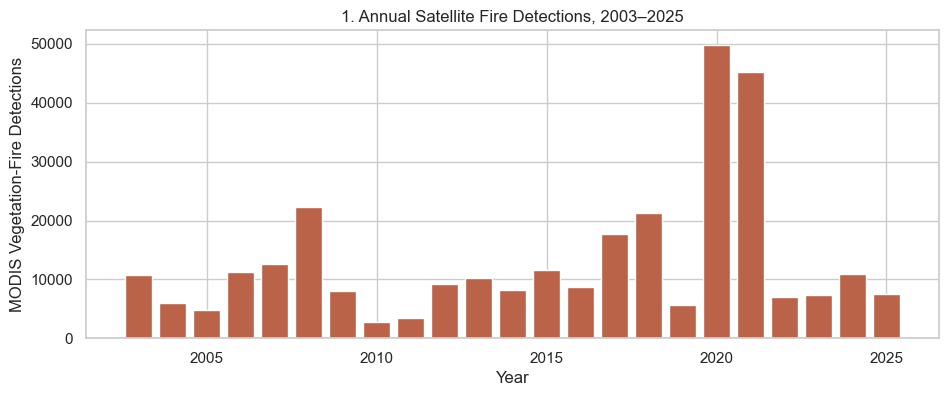

In [12]:
# Graph 1
fig, ax = plt.subplots(figsize=(11, 4))

ax.bar(
    annual_fires["year"],
    annual_fires["fire_detections"],
    color="#ba6348"
)

ax.set(
    title="1. Annual Satellite Fire Detections, 2003–2025",
    xlabel="Year",
    ylabel="MODIS Vegetation-Fire Detections"
)

plt.show()

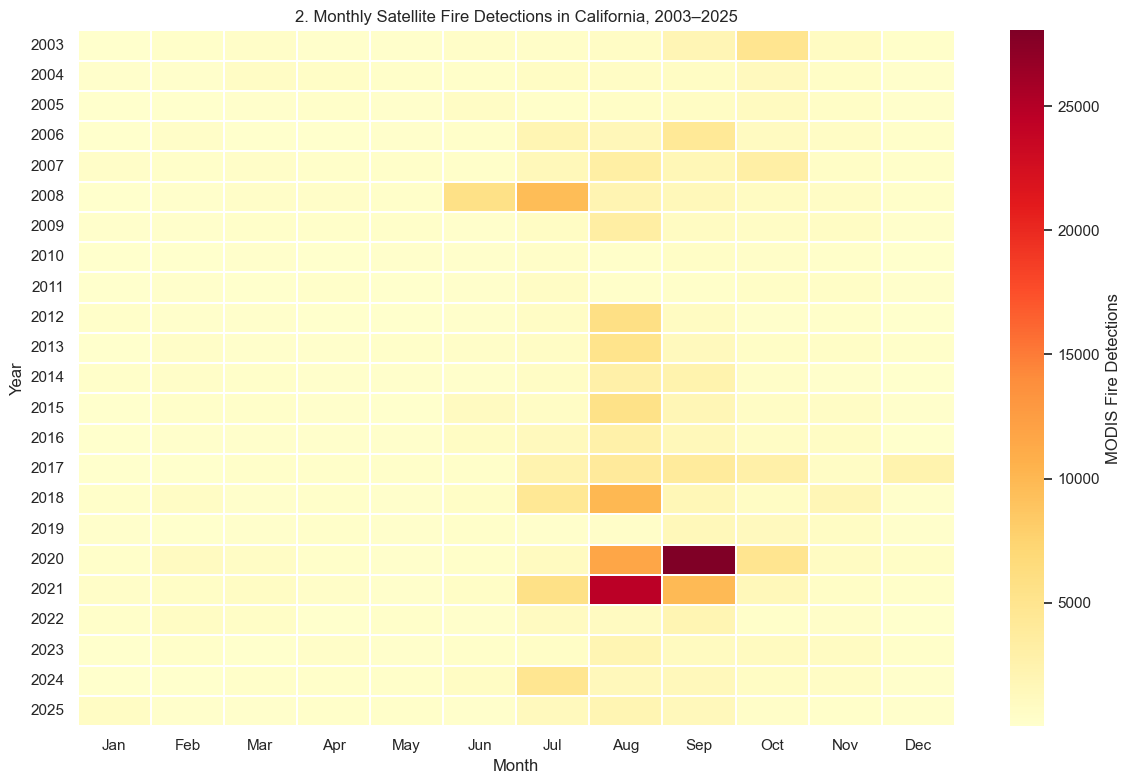

In [13]:
# Graph 2
# Create year-by-month matrix
heatmap_data = monthly_fires.pivot(
    index="year",
    columns="month",
    values="fire_detections"
).fillna(0)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "MODIS Fire Detections"},
    ax=ax
)

ax.set(
    title="2. Monthly Satellite Fire Detections in California, 2003–2025",
    xlabel="Month",
    ylabel="Year"
)

ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

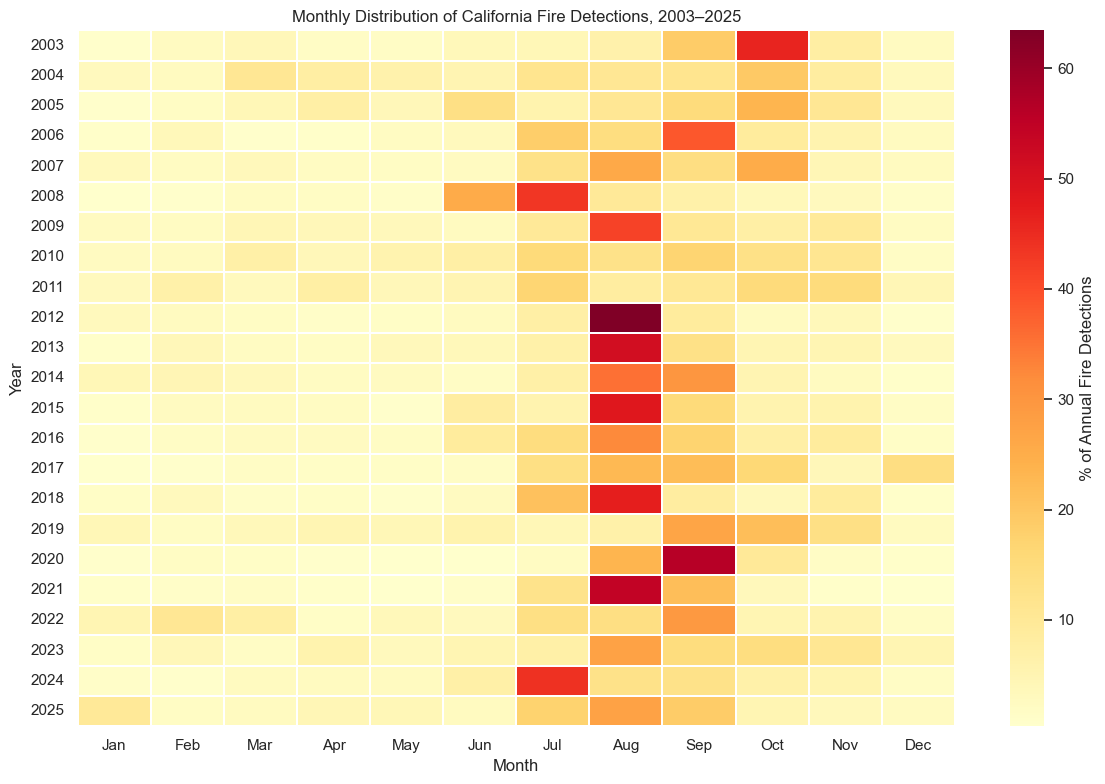

In [14]:
# Graph 2B
# Convert monthly detection counts into percentages of each year's total
monthly_percent = monthly_fires.copy()

monthly_percent["percent"] = (
    monthly_percent["fire_detections"] /
    monthly_percent.groupby("year")["fire_detections"].transform("sum")
    * 100
)

# Create heatmap matrix
heatmap_percent = monthly_percent.pivot(
    index="year",
    columns="month",
    values="percent"
).reindex(columns=range(1, 13)).fillna(0)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    heatmap_percent,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "% of Annual Fire Detections"},
    ax=ax
)

ax.set(
    title="Monthly Distribution of California Fire Detections, 2003–2025",
    xlabel="Month",
    ylabel="Year"
)

ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

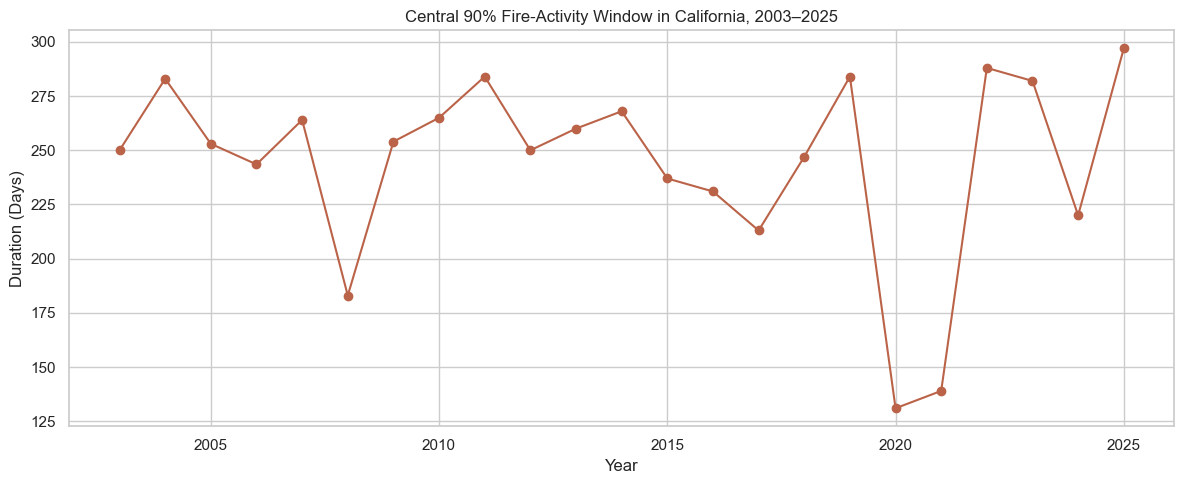

In [15]:
# Graph 3
# Calculate fire-season timing for each year
annual_season = (
    fires.groupby("year")["day_of_year"]
    .agg(
        start=lambda x: x.quantile(0.05),
        end=lambda x: x.quantile(0.95),
        midpoint="median"
    )
    .reset_index()
)

annual_season["duration"] = (
    annual_season["end"] - annual_season["start"]
)

# Plot annual duration
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    annual_season["year"],
    annual_season["duration"],
    marker="o",
    color="#ba6348"
)

ax.set(
    title="Central 90% Fire-Activity Window in California, 2003–2025",
    xlabel="Year",
    ylabel="Duration (Days)"
)

plt.tight_layout()
plt.show()

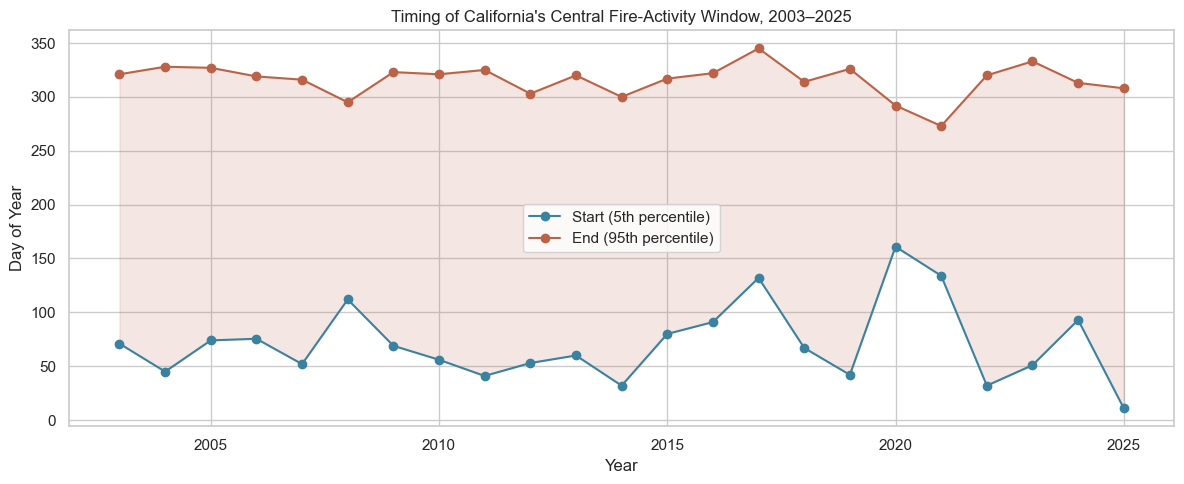

In [16]:
# Graph 4
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    annual_season["year"],
    annual_season["start"],
    marker="o",
    label="Start (5th percentile)",
    color="#3b82a0"
)

ax.plot(
    annual_season["year"],
    annual_season["end"],
    marker="o",
    label="End (95th percentile)",
    color="#ba6348"
)

ax.fill_between(
    annual_season["year"],
    annual_season["start"],
    annual_season["end"],
    alpha=0.15,
    color="#ba6348"
)

ax.set(
    title="Timing of California's Central Fire-Activity Window, 2003–2025",
    xlabel="Year",
    ylabel="Day of Year"
)

ax.legend()
plt.tight_layout()
plt.show()

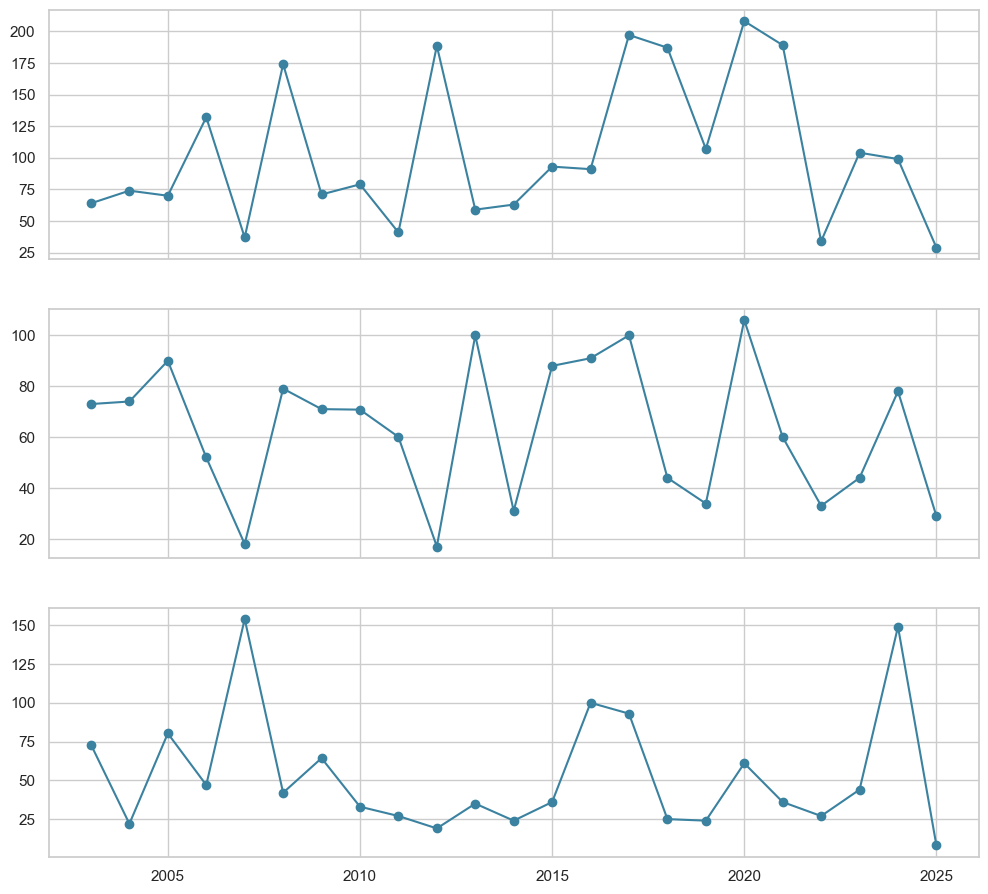

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

regions = [
    "Northern California",
    "Central California",
    "Southern California"
]

for ax, region in zip(axes, regions):
    subset = season_metrics[
        season_metrics["region"] == region
    ].sort_values("year")

    ax.plot(
        subset["year"],
        subset["season_start"],
        marker="o",
        color="#3b82a0",
        label="5th percentile"
    )

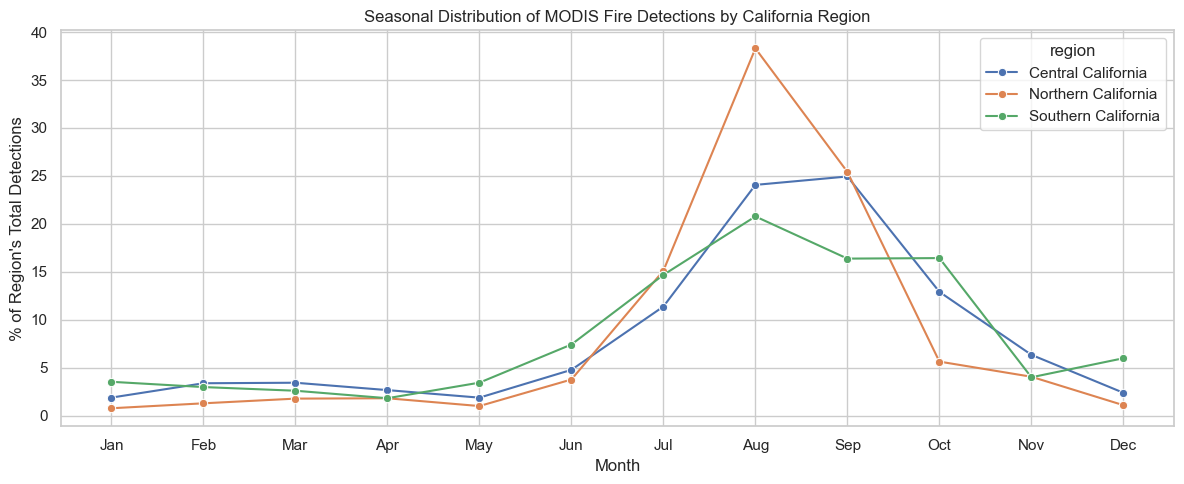

In [18]:
# Calculate monthly fire detections by region
region_month = (
    fires.groupby(["region", "month"])
    .size()
    .reset_index(name="detections")
)

# Normalize within each region
region_month["percent"] = (
    region_month["detections"] /
    region_month.groupby("region")["detections"].transform("sum")
    * 100
)

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=region_month,
    x="month",
    y="percent",
    hue="region",
    marker="o",
    ax=ax
)

ax.set(
    title="Seasonal Distribution of MODIS Fire Detections by California Region",
    xlabel="Month",
    ylabel="% of Region's Total Detections",
    xticks=range(1, 13)
)

ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

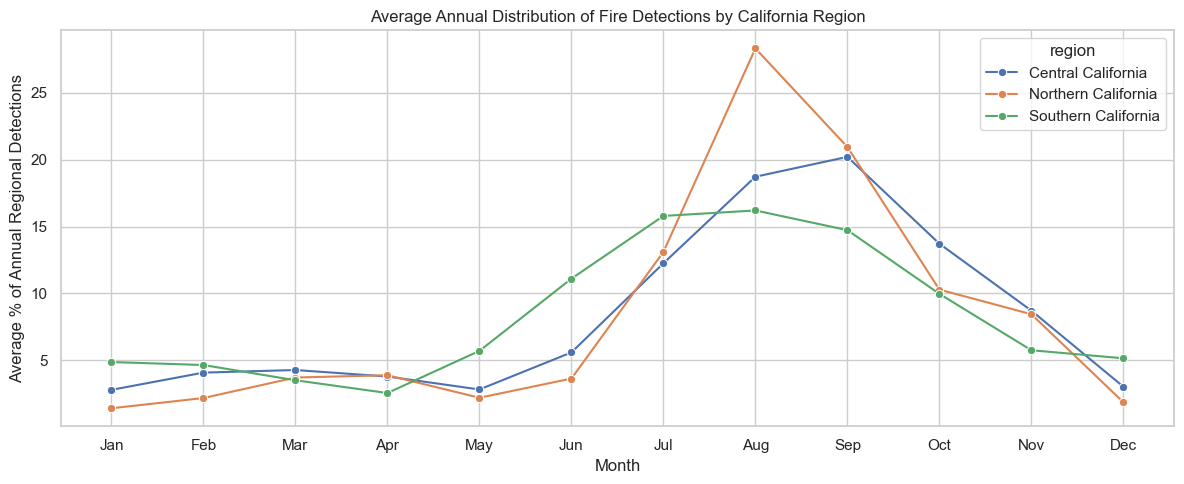

In [19]:
# Count detections for each region, year, and month
region_year_month = (
    fires.groupby(["region", "year", "month"])
    .size()
    .rename("detections")
)

# Include months with zero detections
all_regions = sorted(fires["region"].unique())
all_years = range(2003, 2026)
all_months = range(1, 13)

full_index = pd.MultiIndex.from_product(
    [all_regions, all_years, all_months],
    names=["region", "year", "month"]
)

region_year_month = (
    region_year_month
    .reindex(full_index, fill_value=0)
    .reset_index()
)

# Normalize within each region and year
region_year_month["annual_total"] = (
    region_year_month.groupby(["region", "year"])["detections"]
    .transform("sum")
)

region_year_month["percent"] = np.where(
    region_year_month["annual_total"] > 0,
    region_year_month["detections"] /
    region_year_month["annual_total"] * 100,
    np.nan
)

# Average percentages across years
region_month_avg = (
    region_year_month.groupby(["region", "month"])["percent"]
    .mean()
    .reset_index()
)

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=region_month_avg,
    x="month",
    y="percent",
    hue="region",
    marker="o",
    ax=ax
)

ax.set(
    title="Average Annual Distribution of Fire Detections by California Region",
    xlabel="Month",
    ylabel="Average % of Annual Regional Detections",
    xticks=range(1, 13)
)

ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

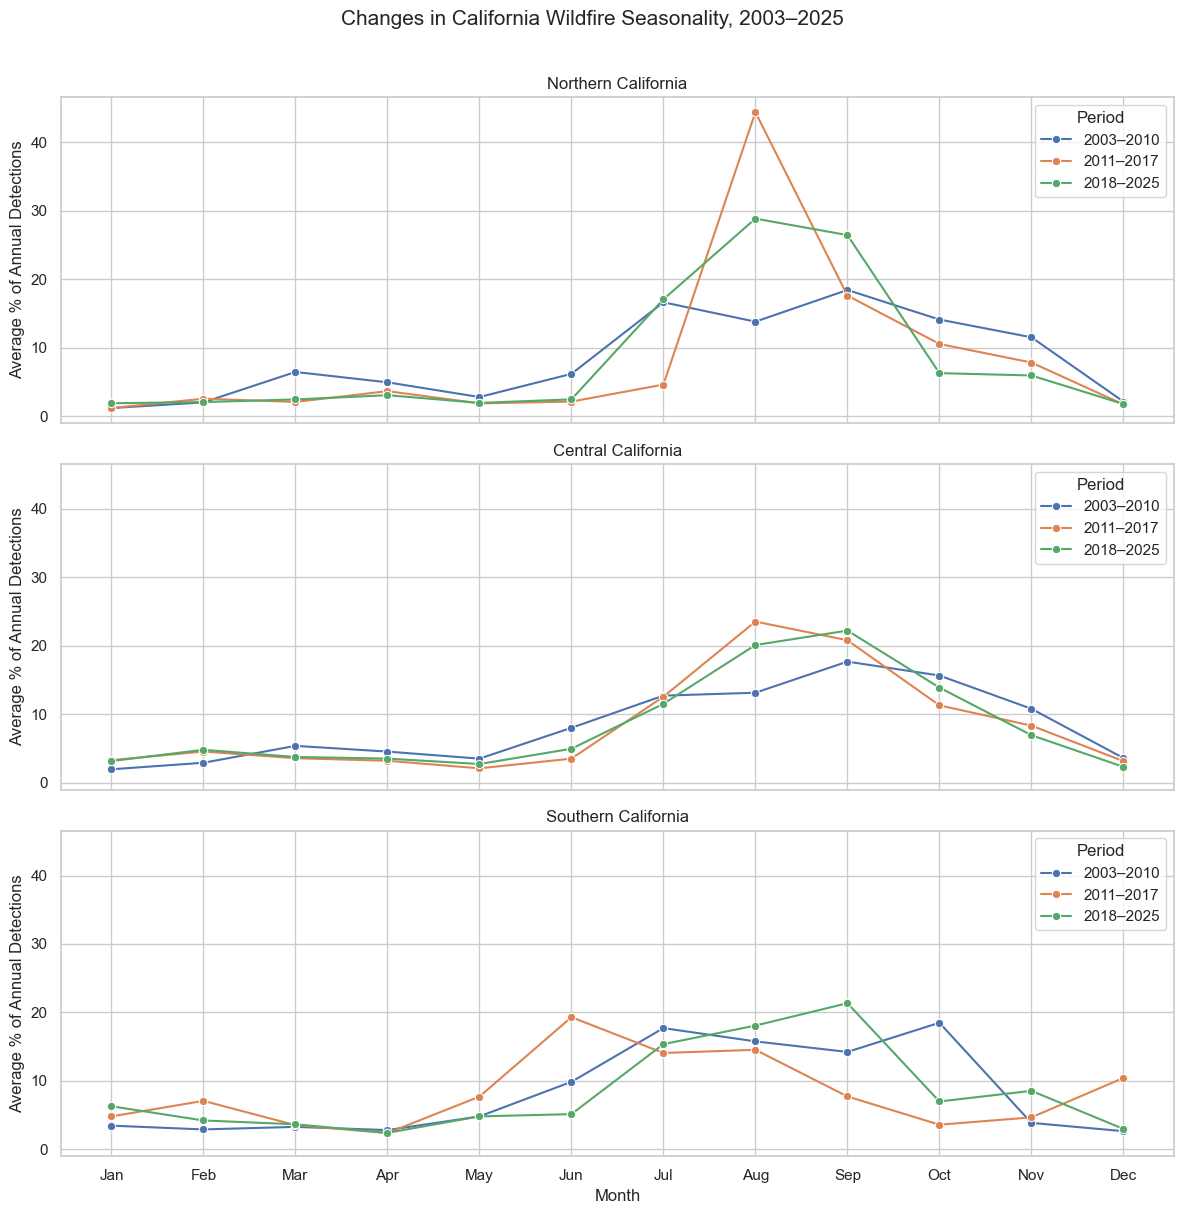

In [20]:
# Assign historical periods to the region-year-month data
region_year_month["period"] = region_year_month["year"].apply(assign_period)

# Average monthly percentages within each historical period
regional_periods = (
    region_year_month
    .groupby(["region", "period", "month"])["percent"]
    .mean()
    .reset_index()
)

# Create three regional plots
regions = [
    "Northern California",
    "Central California",
    "Southern California"
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12),
    sharex=True,
    sharey=True
)

for ax, region in zip(axes, regions):
    subset = regional_periods[
        regional_periods["region"] == region
    ]

    sns.lineplot(
        data=subset,
        x="month",
        y="percent",
        hue="period",
        hue_order=["2003–2010", "2011–2017", "2018–2025"],
        marker="o",
        ax=ax
    )

    ax.set(
        title=region,
        ylabel="Average % of Annual Detections",
        xlabel=""
    )

    ax.legend(title="Period")

axes[-1].set(
    xlabel="Month",
    xticks=range(1, 13)
)

axes[-1].set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

fig.suptitle(
    "Changes in California Wildfire Seasonality, 2003–2025",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()